# Meu Ciclo+ | Clusterização histórica
**Responsável: Lucca.** K-Means para descrever padrões históricos de notificações. Sem classificação de risco ou segurança. Consulte `MODELAGEM.md`.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
candidatos = [Path('modelo'), Path('../modelo'), Path('data-science/modelo')]
pasta = next((p.resolve() for p in candidatos if (p/'ml_sinan.py').is_file()), None)
if pasta is None:
    raise FileNotFoundError('Execute a partir de data-science ou notebooks.')
sys.path.insert(0, str(pasta))
import ml_sinan as ml
base = ml.carregar()
print('Base:', base.shape, 'Total:', base.frequencia.sum())

Base: (270, 3) Total: 2775742


## Engenharia de atributos
Cada UF gera três atributos: média e desvio das nove variações logarítmicas anuais e fração de anos sem aumento. São 27 unidades de agrupamento, não 270 linhas de treino; a dependência geográfica pode existir.

In [2]:
x=ml.atributos_cluster(base)
display(x.head())
r,grupos=ml.executar_clusterizacao()
a=pd.DataFrame(r["avaliacao"])
display(a)
print("k escolhido:",r["k"])
display(pd.DataFrame(r["estabilidade"],index=[0]))

,media_log_crescimento,desvio_log_crescimento,fracao_anos_sem_aumento
uf,,,
Acre,0.039604,0.143902,0.444444
Alagoas,0.140970,0.178533,0.222222
Amapá,0.146576,0.302837,0.222222
Amazonas,0.099833,0.174609,0.222222
Bahia,0.112563,0.194445,0.222222


,k,silhouette,davies_bouldin,inercia,menor_grupo
0,2,0.360686,0.984318,55.710504,5
1,3,0.459130,0.658966,36.855201,2
2,4,0.336412,0.872478,25.939403,2
3,5,0.381531,0.746438,18.092448,2
4,6,0.376421,0.672014,14.292037,2


k escolhido: 2


,metodo,ari_medio,ari_mediano,ari_p10,ari_2015_2023_vs_2015_2024
0,50 subamostras de 80%; ARI sobre as 27 UFs,0.626276,0.634695,-0.056152,0.340248


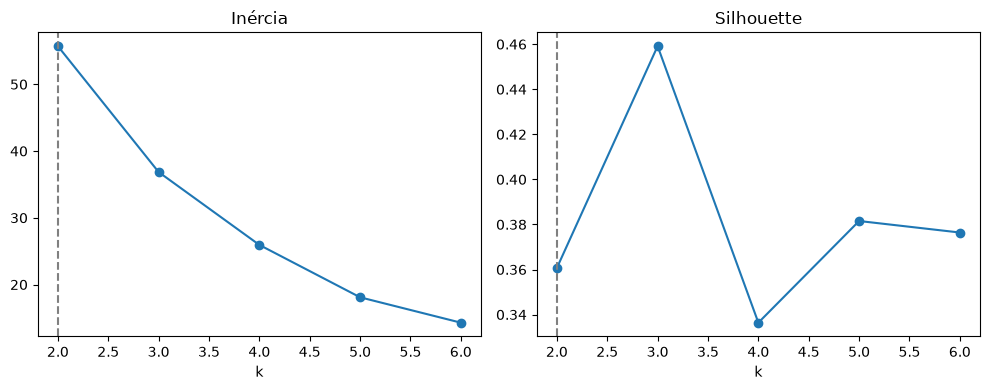

In [3]:
fig,axs=plt.subplots(1,2,figsize=(10,4))
axs[0].plot(a.k,a.inercia,marker="o"); axs[0].set(title="Inércia",xlabel="k")
axs[1].plot(a.k,a.silhouette,marker="o"); axs[1].set(title="Silhouette",xlabel="k")
for ax in axs: ax.axvline(r["k"],linestyle="--",color="gray")
plt.tight_layout(); plt.show()

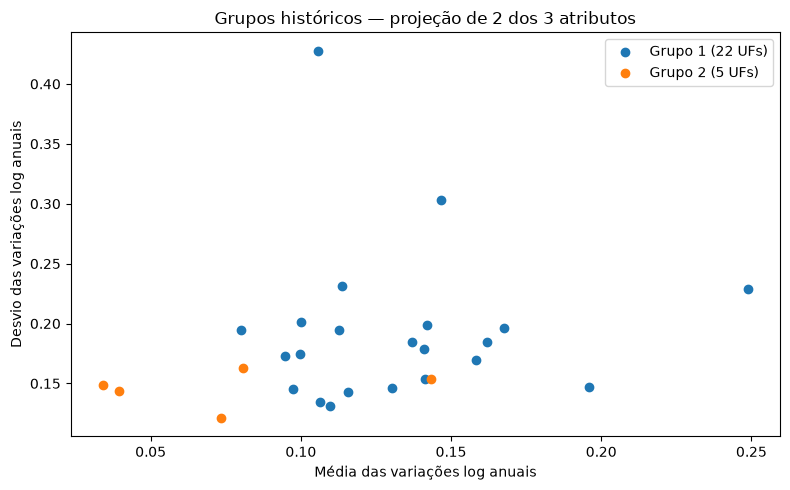

,grupo,quantidade_ufs,ufs,crescimento_geometrico_medio_pct,desvio_log_crescimento_medio,fracao_media_anos_sem_aumento
0,1,22,"[Alagoas, Amapá, Amazonas, Bahia, Ceará, Distr...",14.122819,0.192769,0.166667
1,2,5,"[Acre, Mato Grosso do Sul, Minas Gerais, Rondô...",7.698761,0.146014,0.355556


In [4]:
fig,ax=plt.subplots(figsize=(8,5))
for g,d in grupos.groupby("grupo"):
    ax.scatter(d.media_log_crescimento,d.desvio_log_crescimento,label=f"Grupo {g} ({len(d)} UFs)")
ax.set(xlabel="Média das variações log anuais",ylabel="Desvio das variações log anuais",title="Grupos históricos — projeção de 2 dos 3 atributos")
ax.legend(); plt.tight_layout(); plt.show()
display(pd.DataFrame(r["perfis"]))

## Interpretação e integração
A estabilidade é avaliada por ARI em subamostras e sensibilidade temporal; valores menores indicam instabilidade. IDs de grupos são arbitrários. Não são categorias de risco. O JSON descritivo contém a fonte, os perfis e limitações; integração ao app ainda pendente.